# Predicting How Hard an English Text Is (OneStopEnglish)
**Nhóm 07 – lớp 62FIT4MLA – CLC01.** Notebook dự án sau góp ý giữa kỳ của thầy Khánh.

Notebook làm theo thứ tự góp ý của thầy:
1. Tải dữ liệu và trích đặc trưng (3 đặc trưng gốc + 7 đặc trưng mở rộng).
2. So sánh **chia ngẫu nhiên** và **chia theo bài gốc** (5 fold × 5 lần lặp).
3. Baseline: Flesch-Kincaid, Logistic Regression, Linear SVM, cây nông.
4. Metric: accuracy, QWK, tỷ lệ lỗi hai mức, ma trận nhầm lẫn.
5. Đặc trưng nào phân biệt ba mức; văn bản nào khó phân biệt nhất.
6. Kiểm tra thêm bằng mô hình TF-IDF.
7. Mô hình xác suất (Tuần 9): Naive Bayes, MLE/MAP, log loss, hiệu chỉnh xác suất.
8. Thử trên văn bản ngoài bộ dữ liệu (nhóm tự điền).

Dữ liệu: OneStopEnglish (Vajjala & Lučić, 2018), licence CC BY-SA 4.0.

## 0. Cài đặt và tải dữ liệu

In [1]:
import importlib, subprocess, sys, os
def ensure(pkg, mod=None):
    try: importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.run([sys.executable,'-m','pip','install','-q',pkg,'--break-system-packages'],check=False)
ensure('wordfreq'); ensure('spacy')
try:
    import spacy; spacy.load('en_core_web_sm')
except Exception:
    subprocess.run([sys.executable,'-m','spacy','download','en_core_web_sm'],check=False,
                   env={**os.environ,'PIP_BREAK_SYSTEM_PACKAGES':'1'})

DATA_REPO = 'OneStopEnglishCorpus'
if not os.path.exists(DATA_REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/nishkalavallabhi/OneStopEnglishCorpus.git'],check=True)
BASE = f'{DATA_REPO}/Texts-SeparatedByReadingLevel'
print(os.listdir(BASE))

['Adv-Txt', 'Ele-Txt', 'Int-Txt']


In [2]:
import re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, spacy
from wordfreq import zipf_frequency
from scipy.stats import kruskal
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

LEVELS = {'Elementary': ('Ele-Txt','-ele.txt'), 'Intermediate': ('Int-Txt','-int.txt'), 'Advanced': ('Adv-Txt','-adv.txt')}
ORDER = {'Elementary':0, 'Intermediate':1, 'Advanced':2}
rows = []
for lvl,(d,suf) in LEVELS.items():
    for f in sorted(os.listdir(f'{BASE}/{d}')):
        if f.endswith('.txt'):
            text = open(f'{BASE}/{d}/{f}', encoding='utf-8', errors='ignore').read()
            rows.append(dict(article=f[:-len(suf)], level=lvl, text=text))
data = pd.DataFrame(rows)
print(data.groupby('level').size())
print('Số bài gốc:', data.article.nunique(), '| tổng văn bản:', len(data))
assert data.article.nunique() == 189, 'ID bài gốc sai: mỗi bài phải có đúng 3 phiên bản'

level
Advanced        189
Elementary      189
Intermediate    189
dtype: int64
Số bài gốc: 189 | tổng văn bản: 567


## 1. Trích đặc trưng
- **3 đặc trưng gốc:** độ dài câu, độ dài từ, tỷ lệ từ hiếm (Zipf < 3).
- **7 đặc trưng mở rộng:** Zipf trung bình, tỷ lệ từ ngoài nhóm tần suất cao (Zipf < 4), Zipf phân vị 10, số từ mỗi mệnh đề, số mệnh đề phụ mỗi câu, tỷ lệ từ dài từ 7 chữ, type-token ratio.
- Flesch-Kincaid: số âm tiết đếm xấp xỉ theo nhóm nguyên âm.
- Chưa có Academic Word List nên tỷ lệ từ dài từ 7 chữ chỉ là **chỉ báo thay thế**; nhóm nên thay bằng AWL thật.
- Độ dài văn bản (số từ) được tính để mô tả nhưng **không đưa vào mô hình**, tránh mô hình chỉ học độ dài.

In [3]:
nlp = spacy.load('en_core_web_sm')

def syllables(w):
    w = w.lower(); n = len(re.findall(r'[aeiouy]+', w))
    if w.endswith('e') and n > 1: n -= 1
    return max(n, 1)

def extract(text):
    doc = nlp(re.sub(r'\s+', ' ', text))
    sents = list(doc.sents)
    words = [w for w in doc if w.is_alpha]
    wl = [len(w.text) for w in words]
    z = np.array([zipf_frequency(w.lower_, 'en') for w in words])
    n_clause = sum(1 for w in doc if w.pos_ in ('VERB','AUX') and w.dep_ not in ('aux','auxpass','cop')) or 1
    n_sub = sum(1 for w in doc if w.dep_ in ('advcl','ccomp','acl','relcl','csubj'))
    sent_len = len(words)/len(sents)
    syl = np.mean([syllables(w.text) for w in words])
    return dict(
        sent_len=sent_len, word_len=np.mean(wl), rare_ratio=np.mean(z < 3.0),
        mean_zipf=z.mean(), ratio_outside_top5k=np.mean(z < 4.0), p10_zipf=np.percentile(z, 10),
        words_per_clause=len(words)/n_clause, sub_per_sent=n_sub/len(sents),
        long_word_ratio=np.mean(np.array(wl) >= 7), ttr=len({w.lower_ for w in words})/len(words),
        fk=0.39*sent_len + 11.8*syl - 15.59, n_words=len(words))

CACHE = 'features.csv'
if os.path.exists(CACHE):
    feats = pd.read_csv(CACHE)
else:
    feats = pd.DataFrame([extract(t) for t in data.text]); feats.to_csv(CACHE, index=False)
df = pd.concat([data.drop(columns='text'), feats], axis=1)
y = df.level.map(ORDER).values
groups = df.article.values
S3  = ['sent_len','word_len','rare_ratio']
EXP = S3 + ['mean_zipf','ratio_outside_top5k','p10_zipf','words_per_clause','sub_per_sent','long_word_ratio','ttr']
df.groupby('level')[EXP+['fk','n_words']].mean().loc[list(ORDER)].round(3).T

level,Elementary,Intermediate,Advanced
sent_len,16.643,19.560,21.875
word_len,4.541,4.652,4.730
rare_ratio,0.023,0.030,0.029
mean_zipf,5.826,5.750,5.733
ratio_outside_top5k,0.076,0.094,0.103
p10_zipf,4.203,4.044,3.979
words_per_clause,6.411,6.676,6.619
sub_per_sent,1.060,1.233,1.438
long_word_ratio,0.197,0.220,0.234
ttr,0.456,0.467,0.466


## 2. So sánh chia ngẫu nhiên và chia theo bài gốc
- **Chia ngẫu nhiên:** `StratifiedKFold`; ba phiên bản của một bài có thể nằm hai phía train/test.
- **Chia theo bài gốc:** `StratifiedGroupKFold` với ID bài làm nhóm; ba phiên bản luôn nằm cùng một phía.
- Mỗi cấu hình: 5 fold × 5 lần lặp = 25 lần đánh giá, cùng mô hình và siêu tham số cố định (chưa tune).
- Metric: accuracy, Macro F1, QWK, tỷ lệ lỗi hai mức (Elementary ↔ Advanced).

In [4]:
feature_sets = {'Flesch-Kincaid (1 số)': ['fk'], '3 đặc trưng gốc': S3, 'Mở rộng (10)': EXP}
models = {
    'LR':       lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)),
    'SVM':      lambda: make_pipeline(StandardScaler(), LinearSVC(C=1, max_iter=20000)),
    'Cây nông': lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=0)}

def splitter(kind, X, rep):
    if kind == 'random':
        return StratifiedKFold(5, shuffle=True, random_state=rep).split(X, y)
    return StratifiedGroupKFold(5, shuffle=True, random_state=rep).split(X, y, groups)

def evaluate(kind, X, make_model, reps=5):
    scores, cm = [], np.zeros((3,3), int)
    for rep in range(reps):
        for tr, te in splitter(kind, X, rep):
            p = make_model().fit(X[tr], y[tr]).predict(X[te])
            scores.append((accuracy_score(y[te], p), f1_score(y[te], p, average='macro'),
                           cohen_kappa_score(y[te], p, weights='quadratic'), np.mean(np.abs(p - y[te]) == 2)))
            cm += confusion_matrix(y[te], p, labels=[0,1,2])
    s = np.array(scores)
    return s.mean(0), s.std(0), cm

records, matrices = [], {}
for fs_name, cols in feature_sets.items():
    X = df[cols].values
    for m_name, mk in models.items():
        for kind in ['group', 'random']:
            mean, sd, cm = evaluate(kind, X, mk)
            records.append(dict(features=fs_name, model=m_name, split=kind, accuracy=mean[0], acc_sd=sd[0],
                                macro_f1=mean[1], qwk=mean[2], far_error=mean[3]))
            matrices[(fs_name, m_name, kind)] = cm
results = pd.DataFrame(records); results.to_csv('results.csv', index=False)
print('Đoán một mức cho mọi văn bản: accuracy ≈', round(1/3, 3))

Đoán một mức cho mọi văn bản: accuracy ≈ 0.333


In [5]:
for metric in ['accuracy', 'qwk', 'far_error']:
    print(f'\n=== {metric} (cột: chia theo bài gốc | chia ngẫu nhiên) ===')
    print(results.pivot_table(index=['features','model'], columns='split', values=metric)[['group','random']].round(3))


=== accuracy (cột: chia theo bài gốc | chia ngẫu nhiên) ===
split                           group  random
features              model                  
3 đặc trưng gốc       Cây nông  0.560   0.550
                      LR        0.590   0.584
                      SVM       0.562   0.562
Flesch-Kincaid (1 số) Cây nông  0.514   0.511
                      LR        0.553   0.558
                      SVM       0.540   0.534
Mở rộng (10)          Cây nông  0.556   0.545
                      LR        0.637   0.628
                      SVM       0.627   0.610

=== qwk (cột: chia theo bài gốc | chia ngẫu nhiên) ===
split                           group  random
features              model                  
3 đặc trưng gốc       Cây nông  0.519   0.509
                      LR        0.577   0.571
                      SVM       0.532   0.534
Flesch-Kincaid (1 số) Cây nông  0.461   0.456
                      LR        0.527   0.533
                      SVM       0.506   0.505
Mở rộng (

## 3. Ma trận nhầm lẫn và mức khó phân biệt nhất
Mô hình: LR, đặc trưng mở rộng, chia theo bài gốc (cộng 25 fold).

                    Dự đoán: Elementary  Dự đoán: Intermediate  Dự đoán: Advanced
Thật: Elementary                    717                    171                 57
Thật: Intermediate                  220                    450                275
Thật: Advanced                       90                    216                639
Recall theo mức: {'Elementary': np.float64(0.759), 'Intermediate': np.float64(0.476), 'Advanced': np.float64(0.676)}
Tỷ lệ nhầm Elementary ↔ Advanced: 0.052


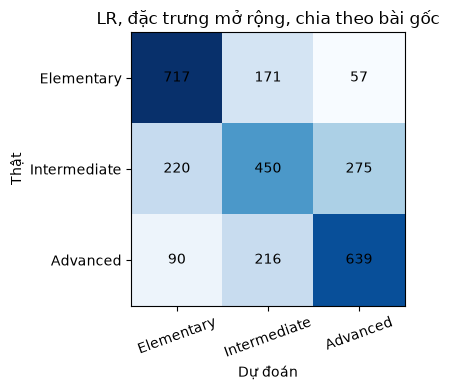

In [6]:
cm = matrices[('Mở rộng (10)', 'LR', 'group')]
names = list(ORDER)
print(pd.DataFrame(cm, index=[f'Thật: {n}' for n in names], columns=[f'Dự đoán: {n}' for n in names]))
print('Recall theo mức:', dict(zip(names, (cm.diagonal()/cm.sum(1)).round(3))))
print('Tỷ lệ nhầm Elementary ↔ Advanced:', round((cm[0,2]+cm[2,0])/cm.sum(), 3))
fig, ax = plt.subplots(figsize=(4.5,4))
ax.imshow(cm, cmap='Blues')
for i in range(3):
    for j in range(3): ax.text(j, i, cm[i,j], ha='center', va='center')
ax.set_xticks(range(3)); ax.set_xticklabels(names, rotation=20); ax.set_yticks(range(3)); ax.set_yticklabels(names)
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thật'); ax.set_title('LR, đặc trưng mở rộng, chia theo bài gốc')
plt.tight_layout(); plt.show()

## 4. Đặc trưng nào phân biệt ba mức
Thống kê Kruskal-Wallis (H càng lớn càng phân biệt tốt) và trung bình theo mức.

In [7]:
rows = []
for c in EXP + ['fk']:
    g3 = [df.loc[df.level == l, c] for l in ORDER]
    rows.append(dict(feature=c, H=kruskal(*g3)[0], **{l[:4]: g.mean() for l, g in zip(ORDER, g3)}))
pd.DataFrame(rows).sort_values('H', ascending=False).round(3).reset_index(drop=True)

,feature,H,Elem,Inte,Adva
0,sent_len,206.155,16.643,19.560,21.875
1,fk,191.300,8.366,10.135,11.382
2,sub_per_sent,92.380,1.060,1.233,1.438
3,ratio_outside_top5k,80.430,0.076,0.094,0.103
4,p10_zipf,77.459,4.203,4.044,3.979
5,long_word_ratio,75.569,0.197,0.220,0.234
6,mean_zipf,70.103,5.826,5.750,5.733
7,word_len,53.247,4.541,4.652,4.730
8,rare_ratio,28.889,0.023,0.030,0.029
9,words_per_clause,11.922,6.411,6.676,6.619


## 5. Văn bản khó phân biệt nhất
Dự đoán out-of-fold bằng LR (đặc trưng mở rộng, chia theo bài gốc); liệt kê các văn bản bị đoán sai **hai mức** và các bài mà cả ba phiên bản bị nhầm nhiều nhất. Nhóm nên đọc trực tiếp các văn bản này.

In [8]:
X = df[EXP].values
oof = np.full(len(df), -1)
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups):
    oof[te] = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(X[tr], y[tr]).predict(X[te])
df['pred'] = oof
df['pred_level'] = df.pred.map({v: k for k, v in ORDER.items()})
df['abs_err'] = np.abs(df.pred - y)
print('Accuracy out-of-fold:', round((df.pred == y).mean(), 3))
far = df[df.abs_err == 2][['article','level','pred_level','sent_len','sub_per_sent']]
print('Số văn bản bị nhầm hai mức:', len(far)); display(far.head(15))
hard = df.groupby('article').abs_err.sum().sort_values(ascending=False).head(10)
print('10 bài gốc có tổng lỗi lớn nhất (cộng ba phiên bản):'); display(hard)

Accuracy out-of-fold: 0.637
Số văn bản bị nhầm hai mức: 28


,article,level,pred_level,sent_len,sub_per_sent
1,Amsterdam,Elementary,Advanced,20.090909,1.636364
5,Billionaires,Elementary,Advanced,19.944444,1.555556
7,Bolivia,Elementary,Advanced,18.387097,1.387097
10,Cigarettes,Elementary,Advanced,20.782609,1.521739
39,Midlife crisis,Elementary,Advanced,19.083333,1.291667
69,WNL Bangladesh factory owners,Elementary,Advanced,21.217391,1.782609
75,WNL Bogus Allergy,Elementary,Advanced,18.925926,1.740741
99,WNL Glastonbury,Elementary,Advanced,16.190476,0.714286
106,WNL Icelandic names,Elementary,Advanced,18.160000,1.120000
149,WNL Ships noise,Elementary,Advanced,17.718750,1.312500


10 bài gốc có tổng lỗi lớn nhất (cộng ba phiên bản):


article
Amsterdam            3
Bolivia              3
Cigarettes           3
Billionaires         3
Fitness              3
Gangs                3
Japan                3
Norwegian sun        3
Midlife crisis       3
WNL Canadian Pair    3
Name: abs_err, dtype: int64

## 6. Kiểm tra thêm: mô hình TF-IDF
Mô hình dung lượng cao có thể học từ vựng chủ đề của từng bài. Kiểm tra xem hai cách chia cho kết quả ra sao với TF-IDF n-gram (1 đến 2) + LR, 3 lần lặp.
Kết quả lần chạy của nhóm: chia theo bài gốc ≈ 0,84 accuracy, chia ngẫu nhiên ≈ 0,34. **Kết quả này bất ngờ (đảo chiều so với giả thuyết rò rỉ); cần kiểm tra lại trước khi kết luận trong bài.**

In [9]:
texts = data.text.values
tfidf_res = {}
for kind in ['group', 'random']:
    acc, qwk = [], []
    for rep in range(3):
        for tr, te in splitter(kind, texts, rep):
            m = make_pipeline(TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True),
                              LogisticRegression(C=30, max_iter=3000)).fit(texts[tr], y[tr])
            p = m.predict(texts[te])
            acc.append(accuracy_score(y[te], p)); qwk.append(cohen_kappa_score(y[te], p, weights='quadratic'))
    tfidf_res[kind] = (np.mean(acc), np.mean(qwk))
pd.DataFrame(tfidf_res, index=['accuracy','qwk']).T.round(3)

,accuracy,qwk
group,0.841,0.868
random,0.336,0.369


## 7. Mô hình xác suất (nội dung Tuần 8)
Mục này đưa các ý của bài giảng *Probabilistic Models* (Week 8, Part 1 và Part 2) vào bài toán phân loại ba mức. Chuỗi suy luận của bài giảng: **lịch sử / đặc trưng → đếm hoặc ước lượng tham số → dự đoán → kiểm tra trên dữ liệu held-out → giáo viên quyết định**.

| Ý trong bài giảng | Áp dụng trong notebook | Mục |
|---|---|---|
| Likelihood, MLE = k/n, trường hợp biên hợp lệ | tỉ lệ "đặc trưng có mặt" trong từng lớp; kiểm tra lại ví dụ L07 | 7.1 |
| Naive Bayes: đếm trong lớp → chọn thừa số có mặt / vắng mặt → nhân → chuẩn hoá | Bernoulli NB viết tay; tái hiện ví dụ 8 bản ghi của slide | 7.1 |
| Posterior, MAP, mean, predictive: chọn đối tượng theo câu hỏi | hàm `beta_objects` | 7.1 |
| Log loss phạt nặng dự đoán sai mà tự tin; luôn so với baseline | baseline tỉ lệ lớp, LR, Gaussian NB, Bernoulli NB; thêm Brier | 7.2 |
| Xác suất đúng khác với lớp đúng (calibration, Route A) | biểu đồ độ tin cậy, ECE, temperature scaling trên tập hiệu chỉnh riêng | 7.3 |
| Zero-count làm một lớp bị loại; làm mịn Beta(2,2) cho MAP = (k+1)/(n+2); sức mạnh prior | MLE và MAP khi dữ liệu train ít | 7.4 |
| NB giả định độc lập có điều kiện (Route B) | tương quan giữa các đặc trưng trong cùng một mức | 7.5 |

Khác biệt so với bài giảng: nhãn có **ba lớp** nên prior của lớp là phân phối categorical (Dirichlet là mở rộng tuỳ chọn của Beta); đặc trưng là **số thực** nên Bernoulli NB phải nhị phân hoá theo **trung vị của tập train** (ngưỡng không bao giờ nhìn vào fold test). Tỉ lệ "đặc trưng có mặt" trong mỗi lớp vẫn là Bernoulli / Beta như bài giảng. Các phép đánh giá dùng cùng cách chia theo bài gốc như mục 2.

### 7.1 Công cụ: MLE / MAP, Naive Bayes viết tay, log loss
Ô dưới định nghĩa các hàm dùng cho cả mục 7, rồi **kiểm tra lại các con số trong slide** (ví dụ L07 và 8 bản ghi NB) bằng `assert` để chắc rằng cài đặt đúng trước khi áp vào dữ liệu thật.

In [10]:
from scipy.special import logsumexp
from scipy.optimize import minimize_scalar
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit

EPS = 1e-6   # cắt xác suất khi tính log loss (giao thức của slide: ε = 1e-6), chỉ là quy ước số học

def log_loss_eps(y_true, proba, eps=EPS):
    """Log loss trung bình trên từng văn bản (nat); thấp hơn là tốt hơn."""
    p = np.clip(proba[np.arange(len(y_true)), y_true], eps, 1.0)
    return float(-np.mean(np.log(p)))

def brier(y_true, proba):
    """Brier score nhiều lớp: sai số bình phương của vector xác suất."""
    return float(np.mean(np.sum((proba - np.eye(proba.shape[1])[y_true]) ** 2, axis=1)))

def beta_objects(k, n, a=2, b=2):
    """Bốn đối tượng khác nhau cho tỉ lệ θ sau k thành công / n lần, prior Beta(a, b)."""
    a2, b2 = a + k, b + n - k
    return dict(posterior=f'Beta({a2},{b2})',
                MLE=k / n if n else np.nan,
                MAP=(a2 - 1) / (a2 + b2 - 2) if a2 > 1 and b2 > 1 else np.nan,   # công thức mode nội điểm
                mean=a2 / (a2 + b2),
                predictive=a2 / (a2 + b2))   # P(lần sau đúng | D) = E[θ | D]

class BernoulliNBManual:
    """Naive Bayes nhị phân làm đúng theo slide: đếm trong từng lớp -> chọn thừa số present/absent -> nhân -> chuẩn hoá.
    a = 1: MLE (k/n).  a = 2: MAP với prior Beta(2,2), tức (k+1)/(n+2).  a lớn hơn: prior Beta(a,a) mạnh hơn (cùng trung bình 0,5)."""
    def __init__(self, a=1.0, binarize=True):
        self.a, self.binarize = a, binarize

    def _bits(self, X):
        X = np.asarray(X, float)
        return (X > self.thr_).astype(int) if self.binarize else X.astype(int)

    def fit(self, X, y):
        X = np.asarray(X, float)
        self.thr_ = np.median(X, axis=0) if self.binarize else None   # chỉ tính từ tập train
        B = self._bits(X)
        self.classes_ = np.unique(y)
        n = np.array([(y == c).sum() for c in self.classes_])[:, None]
        k = np.array([B[y == c].sum(0) for c in self.classes_])
        self.prior_ = n.ravel() / n.sum()
        self.theta_ = (k + self.a - 1) / (n + 2 * self.a - 2)          # tỉ lệ "có mặt" trong từng lớp
        return self

    def scores(self, X):
        """Điểm chưa chuẩn hoá s_c = P(c) * tích các thừa số đã chọn (không phải xác suất, không cộng lại bằng 1)."""
        B = self._bits(X)
        return np.array([self.prior_[c] * np.where(B == 1, self.theta_[c], 1 - self.theta_[c]).prod(1)
                         for c in range(len(self.classes_))]).T

    def predict_proba(self, X):
        B = self._bits(X); K = len(self.classes_)
        with np.errstate(divide='ignore', invalid='ignore'):
            logs = np.array([np.log(self.prior_[c]) + np.where(B == 1, np.log(self.theta_[c]), np.log(1 - self.theta_[c])).sum(1)
                             for c in range(K)]).T
            tot = logsumexp(logs, axis=1, keepdims=True)           # chuẩn hoá bằng log-sum-exp
            P = np.exp(logs - tot)
        P[~np.isfinite(tot.ravel())] = 1.0 / K                     # mọi lớp bị loại: không có thông tin
        return P

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(1)]

# --- Kiểm tra bằng ví dụ của slide: 8 bản ghi, mỗi lớp 4; đặc trưng (struggled, long time, hint) ---
toy_X = np.array([[1,1,0],[0,0,0],[0,0,0],[0,0,0], [1,1,1],[1,1,1],[1,1,1],[0,0,0]])
toy_y = np.array([0,0,0,0,1,1,1,1])
for a, label in [(1, 'MLE (k/n)'), (2, 'MAP Beta(2,2) = (k+1)/(n+2)')]:
    nb = BernoulliNBManual(a=a, binarize=False).fit(toy_X, toy_y)
    for x in ([1,0,0], [1,0,1]):
        print(f'{label:30s} x={tuple(x)}  điểm s={nb.scores([x])[0].round(4)}  P(lớp|x)={nb.predict_proba([x])[0].round(3)}')
nb1, nb2 = BernoulliNBManual(a=1, binarize=False).fit(toy_X, toy_y), BernoulliNBManual(a=2, binarize=False).fit(toy_X, toy_y)
assert np.allclose(nb1.scores([[1,0,0]]), [[3/32, 3/128]]) and np.allclose(nb1.predict_proba([[1,0,0]]), [[.8, .2]])
assert np.allclose(nb1.predict_proba([[1,0,1]]), [[0, 1]])        # thừa số 0/4 chọn bởi hint = 1 loại hẳn lớp 0
assert np.allclose(nb2.predict_proba([[1,0,1]]), [[.2, .8]])      # làm mịn: không lớp nào bị loại
print('Các phép tính khớp slide.')

# --- Bốn đối tượng khác nhau cho cùng lịch sử L07 (3 đúng / 10) ---
L07 = pd.DataFrame({'Beta(2,2)': beta_objects(3, 10, 2, 2), 'Beta(5,5)': beta_objects(3, 10, 5, 5)})
assert np.isclose(L07.loc['MAP', 'Beta(2,2)'], 1/3) and np.isclose(L07.loc['mean', 'Beta(2,2)'], 5/14)
display(L07)

MLE (k/n)                      x=(1, 0, 0)  điểm s=[0.0938 0.0234]  P(lớp|x)=[0.8 0.2]
MLE (k/n)                      x=(1, 0, 1)  điểm s=[0.     0.0703]  P(lớp|x)=[0. 1.]
MAP Beta(2,2) = (k+1)/(n+2)    x=(1, 0, 0)  điểm s=[0.0926 0.037 ]  P(lớp|x)=[0.714 0.286]
MAP Beta(2,2) = (k+1)/(n+2)    x=(1, 0, 1)  điểm s=[0.0185 0.0741]  P(lớp|x)=[0.2 0.8]
Các phép tính khớp slide.


,"Beta(2,2)","Beta(5,5)"
posterior,"Beta(5,9)","Beta(8,12)"
MLE,0.3,0.3
MAP,0.333333,0.388889
mean,0.357143,0.4
predictive,0.357143,0.4


### 7.2 So sánh với baseline bằng log loss
Câu hỏi: **xác suất** mà mô hình đưa ra có tốt hơn việc chỉ dùng tỉ lệ ba lớp trong tập train không? Baseline chỉ dùng tập train (không dùng fold test). Các mô hình dùng 10 đặc trưng mở rộng, chia theo bài gốc, 5 fold × 5 lần lặp. Giá trị là trung bình ± độ lệch chuẩn giữa các fold; đây **không** phải khoảng tin cậy hay kiểm định ý nghĩa. Log loss thấp hơn là tốt hơn; baseline cho ln 3 ≈ 1,099 khi ba lớp cân bằng.

In [11]:
X8 = df[EXP].values
prob_models = {
    'Baseline: tỉ lệ lớp (prior)':   lambda: DummyClassifier(strategy='prior'),
    'LR (chuẩn hoá)':                lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)),
    'Gaussian NB':                   lambda: GaussianNB(),
    'Bernoulli NB, MLE (a=1)':       lambda: BernoulliNBManual(a=1),
    'Bernoulli NB, MAP Beta(2,2)':   lambda: BernoulliNBManual(a=2),
}
rows = []
for name, mk in prob_models.items():
    for rep in range(5):
        for tr, te in splitter('group', X8, rep):
            P = mk().fit(X8[tr], y[tr]).predict_proba(X8[te]); pred = P.argmax(1)
            rows.append(dict(model=name, accuracy=accuracy_score(y[te], pred),
                             qwk=cohen_kappa_score(y[te], pred, weights='quadratic'),
                             log_loss=log_loss_eps(y[te], P), brier=brier(y[te], P)))
res8 = pd.DataFrame(rows); res8.to_csv('results_week8.csv', index=False)
g = res8.groupby('model', sort=False)
summary8 = g.mean().round(3).astype(str) + ' ± ' + g.std().round(3).astype(str)
display(summary8)

,accuracy,qwk,log_loss,brier
model,,,,
Baseline: tỉ lệ lớp (prior),0.333 ± 0.0,0.0 ± 0.0,1.099 ± 0.0,0.667 ± 0.0
LR (chuẩn hoá),0.637 ± 0.043,0.623 ± 0.059,0.795 ± 0.059,0.473 ± 0.03
Gaussian NB,0.561 ± 0.037,0.506 ± 0.053,1.181 ± 0.189,0.591 ± 0.054
"Bernoulli NB, MLE (a=1)",0.53 ± 0.036,0.46 ± 0.059,1.104 ± 0.108,0.619 ± 0.046
"Bernoulli NB, MAP Beta(2,2)",0.53 ± 0.036,0.46 ± 0.059,1.099 ± 0.106,0.618 ± 0.046


### 7.3 Xác suất có đáng tin không? Biểu đồ độ tin cậy và temperature scaling
Độ chính xác cao chưa có nghĩa xác suất đáng tin (Guo và cộng sự, 2017). Ta so **trước và sau** khi chia nhiệt độ cho logit của LR. Nhiệt độ T chỉ được ước lượng trên **tập hiệu chỉnh riêng** (25% số bài gốc của tập train, tách theo nhóm), còn fold test không bị đụng tới. Bên trong mỗi fold: LR học trên 75% bài của tập train, T học trên 25% còn lại, rồi đánh giá trên fold test.

Nhiệt độ T học được (trung bình ± sd): 0.95 ± 0.207 (T > 1 làm xác suất mềm hơn)


log_loss         brier           ece       
                   mean    std   mean    std   mean    std
stage                                                     
trước (T=1)       0.797  0.050  0.476  0.027  0.078  0.023
sau (T đã học)    0.810  0.056  0.480  0.029  0.089  0.027

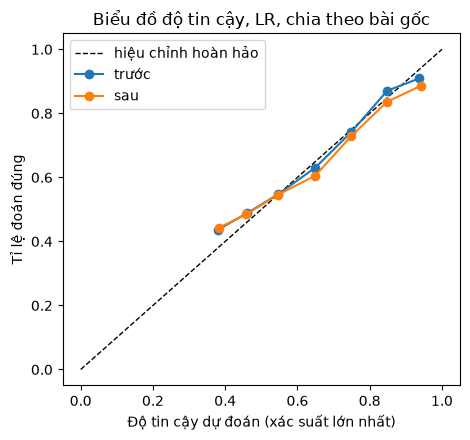

In [12]:
def softmax_T(z, T):
    s = z / T; s = s - s.max(1, keepdims=True); e = np.exp(s)
    return e / e.sum(1, keepdims=True)

def fit_T(z, y_true):
    return minimize_scalar(lambda T: log_loss_eps(y_true, softmax_T(z, T)), bounds=(0.05, 20), method='bounded').x

def reliability(P, y_true, bins=10):
    conf, ok = P.max(1), (P.argmax(1) == y_true)
    edges = np.linspace(0, 1, bins + 1); xs, ys, ns = [], [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): xs.append(conf[m].mean()); ys.append(ok[m].mean()); ns.append(int(m.sum()))
    return np.array(xs), np.array(ys), np.array(ns)

def ece(P, y_true, bins=10):
    xs, ys, ns = reliability(P, y_true, bins)
    return float(np.sum(ns / ns.sum() * np.abs(ys - xs)))

cal_rows, PB, PA, YT = [], [], [], []
for rep in range(3):
    for tr, te in splitter('group', X8, rep):
        fit_i, cal_i = next(GroupShuffleSplit(1, test_size=0.25, random_state=rep).split(tr, groups=groups[tr]))
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(X8[tr][fit_i], y[tr][fit_i])
        T = fit_T(m.decision_function(X8[tr][cal_i]), y[tr][cal_i])
        z = m.decision_function(X8[te]); Pb, Pa = softmax_T(z, 1.0), softmax_T(z, T)
        for tag, P in [('trước (T=1)', Pb), ('sau (T đã học)', Pa)]:
            cal_rows.append(dict(stage=tag, log_loss=log_loss_eps(y[te], P), brier=brier(y[te], P), ece=ece(P, y[te]), T=T))
        PB.append(Pb); PA.append(Pa); YT.append(y[te])
cal = pd.DataFrame(cal_rows)
print('Nhiệt độ T học được (trung bình ± sd):', round(cal['T'].mean(), 3), '±', round(cal['T'].std(), 3), '(T > 1 làm xác suất mềm hơn)')
display(cal.groupby('stage', sort=False)[['log_loss', 'brier', 'ece']].agg(['mean', 'std']).round(3))

PB, PA, YT = np.vstack(PB), np.vstack(PA), np.concatenate(YT)
fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='hiệu chỉnh hoàn hảo')
for P, lab in [(PB, 'trước'), (PA, 'sau')]:
    xs, ys, _ = reliability(P, YT); ax.plot(xs, ys, 'o-', label=lab)
ax.set_xlabel('Độ tin cậy dự đoán (xác suất lớn nhất)'); ax.set_ylabel('Tỉ lệ đoán đúng')
ax.set_title('Biểu đồ độ tin cậy, LR, chia theo bài gốc'); ax.legend(); plt.tight_layout(); plt.show()

### 7.4 Dữ liệu ít: MLE dễ gãy, prior cho thêm "sức mạnh"
Mô phỏng ý của slide về nhóm dữ liệu ít: chỉ dùng **m bài gốc** (mỗi bài đủ 3 phiên bản) trong tập train để ước lượng tỉ lệ trong lớp, rồi tính log loss trên fold test cố định. `a = 1` là MLE (k/n); `a = 2` là MAP với Beta(2,2) (cộng một); `a = 5, 10` là prior Beta(a,a) mạnh hơn nhưng **cùng trung bình 0,5**. Cột "có biên" là tỉ lệ lần chạy mà MLE có ít nhất một tỉ lệ đúng 0 hoặc 1 (một thừa số 0 loại cả lớp khi vector đặc trưng chọn đúng thừa số đó). Prior mạnh hơn không đồng nghĩa với đúng hơn; kết quả phụ thuộc vào dữ liệu và prior.

In [13]:
sizes, a_values, rows = [3, 6, 12, 30, 60], [1, 2, 5, 10], []
for rep in range(3):
    rng = np.random.default_rng(rep)
    for tr, te in splitter('group', X8, rep):
        tr_articles = np.unique(groups[tr])
        for m_ in sizes:
            sub = tr[np.isin(groups[tr], rng.choice(tr_articles, size=m_, replace=False))]
            for a in a_values:
                nbm = BernoulliNBManual(a=a).fit(X8[sub], y[sub]); P = nbm.predict_proba(X8[te])
                rows.append(dict(articles=m_, a=a, log_loss=log_loss_eps(y[te], P),
                                 accuracy=accuracy_score(y[te], P.argmax(1)),
                                 boundary=bool(((nbm.theta_ == 0) | (nbm.theta_ == 1)).any())))
low = pd.DataFrame(rows)
print('Log loss trung bình theo số bài gốc dùng để fit (hàng) và a (cột); baseline tỉ lệ lớp = ln 3 ≈', round(np.log(3), 3))
display(low.pivot_table(index='articles', columns='a', values='log_loss').round(3))
print('Tỉ lệ lần chạy MLE (a=1) có tỉ lệ biên 0 hoặc 1:')
display(low[low.a == 1].groupby('articles').boundary.mean().round(2).to_frame('có biên'))

Log loss trung bình theo số bài gốc dùng để fit (hàng) và a (cột); baseline tỉ lệ lớp = ln 3 ≈ 1.099


a,1,2,5,10
articles,,,,
3,5.664,1.339,1.045,1.025
6,2.090,1.197,1.016,0.991
12,1.223,1.131,1.015,0.971
30,1.222,1.182,1.100,1.027
60,1.096,1.082,1.048,1.009


Tỉ lệ lần chạy MLE (a=1) có tỉ lệ biên 0 hoặc 1:


,có biên
articles,
3,1.00
6,0.53
12,0.00
30,0.00
60,0.00


### 7.5 Giả định độc lập có điều kiện của NB
NB coi các đặc trưng độc lập **khi đã biết mức**. Làm mịn không bỏ được giả định này. Ô dưới đo tương quan giữa các đặc trưng sau khi trừ trung bình từng mức; các cặp tương quan mạnh cho thấy NB có thể đếm cùng một bằng chứng nhiều lần, làm xác suất quá tự tin. Đây chỉ là kiểm tra mô tả, chưa chứng minh sự phụ thuộc là nguyên nhân của từng lỗi.

In [14]:
Z = df[EXP] - df.groupby('level')[EXP].transform('mean')
C = Z.corr()
pairs = [(EXP[i], EXP[j], C.iloc[i, j]) for i in range(len(EXP)) for j in range(i + 1, len(EXP))]
top = (pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'r_trong_mức'])
         .assign(abs_r=lambda d: d.r_trong_mức.abs()).sort_values('abs_r', ascending=False).head(8).drop(columns='abs_r'))
display(top.round(3).reset_index(drop=True))

,feature_1,feature_2,r_trong_mức
0,ratio_outside_top5k,p10_zipf,-0.946
1,word_len,long_word_ratio,0.912
2,mean_zipf,ratio_outside_top5k,-0.805
3,mean_zipf,p10_zipf,0.792
4,rare_ratio,ratio_outside_top5k,0.698
5,rare_ratio,p10_zipf,-0.669
6,sent_len,sub_per_sent,0.655
7,rare_ratio,mean_zipf,-0.634


### 7.6 Cách đọc kết quả mục 7
- Đọc từng chỉ số **so với baseline tỉ lệ lớp** (log loss ≈ 1,099 và accuracy ≈ 0,33), không so với một mốc chọn tuỳ ý.
- Ghi rõ đơn vị và seed: log loss tính bằng nat trên mỗi văn bản, cắt ở 1e-6; mục 7.2 dùng seed lặp 0 đến 4, mục 7.3 và 7.4 dùng seed 0 đến 2. Dấu ± là độ lệch chuẩn giữa các fold.
- Không kết luận: làm mịn NB tự động hiệu chỉnh xác suất; temperature scaling luôn cải thiện mô hình; log loss tốt hơn chứng minh công cụ hỗ trợ học tập hiệu quả. Ba lần lặp chỉ là kiểm tra thăm dò.
- Xác suất chỉ là gợi ý cho giáo viên (ví dụ văn bản sát ranh giới giữa hai mức); giáo viên giữ quyết định cuối cùng.
- **Kết quả lần chạy của nhóm (chia theo bài gốc, 5 fold × 5 lần lặp ở mục 7.2):** LR có log loss thấp nhất, 0,795 ± 0,059, so với baseline tỉ lệ lớp 1,099; accuracy 0,637 và QWK 0,623.
- Gaussian NB có log loss 1,181 ± 0,189, **tệ hơn baseline**, dù accuracy 0,561 vẫn cao hơn mức đoán bừa 0,333. Bernoulli NB có log loss 1,104 (MLE) và 1,099 (MAP Beta(2,2)), tức xấp xỉ baseline, với accuracy 0,530. Vậy NB đoán đúng lớp tốt hơn đoán bừa, nhưng xác suất của nó không tốt hơn việc chỉ dùng tỉ lệ lớp.
- Mục 7.5 gợi ý một nguyên nhân có thể: các đặc trưng phụ thuộc mạnh trong cùng một mức (|r| = 0,946 giữa ratio_outside_top5k và p10_zipf; 0,912 giữa word_len và long_word_ratio), nên NB đếm trùng bằng chứng. Đây mới là gợi ý, chưa được kiểm chứng (nhóm có thể thử bỏ bớt đặc trưng trùng rồi chạy lại).
- Temperature scaling (mục 7.3, 3 lần lặp) **không cải thiện**: T học được 0,95 ± 0,21; log loss 0,797 sang 0,810 và ECE 0,078 sang 0,089. Chưa thấy LR bị lệch hiệu chỉnh rõ, và chênh lệch nhỏ so với độ lệch chuẩn giữa các fold.
- Dữ liệu ít (mục 7.4): với 3 bài gốc, MLE có tỉ lệ biên 0 hoặc 1 ở 100% lần chạy và log loss 5,664 (baseline 1,099); với 6 bài là 53% và 2,090; từ 12 bài trở lên không còn tỉ lệ biên. Prior Beta(10,10) có log loss thấp nhất ở mọi cỡ mẫu thử (1,025; 0,991; 0,971; 1,027; 1,009 cho 3, 6, 12, 30, 60 bài), thấp hơn baseline nhưng chênh lệch nhỏ. Có thể prior mạnh giúp vì kéo xác suất của NB về mềm hơn; đây chưa phải kết luận.
- Giới hạn: 3 đến 5 lần lặp; dấu ± là độ lệch chuẩn giữa các fold, không phải khoảng tin cậy; bộ dữ liệu chỉ có 189 bài gốc; log loss tốt hơn baseline chưa chứng minh công cụ hỗ trợ học tập hiệu quả.

## 8. Thử trên văn bản ngoài bộ dữ liệu
Nhóm **tự chọn và điền** 5 văn bản (nguồn công khai, ghi rõ nguồn) vào `EXTERNAL_TEXTS`, kèm mức nhóm tự gán sau khi thảo luận. Mô hình trả về mức dự đoán và xác suất; xác suất giúp giáo viên thấy văn bản sát ranh giới.

In [15]:
final_model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(df[EXP].values, y)
inv = {v: k for k, v in ORDER.items()}

def predict_level(text):
    f = pd.DataFrame([extract(text)])[EXP].values
    proba = final_model.predict_proba(f)[0]
    return inv[int(proba.argmax())], dict(zip(inv.values(), proba.round(3)))

# Điền 5 văn bản: {'tên/nguồn': ('nội dung văn bản', 'mức nhóm gán hoặc None')}
EXTERNAL_TEXTS = {
    # 'Nguồn 1': ('...', 'Intermediate'),
}
if not EXTERNAL_TEXTS:
    print('Chưa có văn bản ngoài bộ dữ liệu. Điền vào EXTERNAL_TEXTS rồi chạy lại ô này.')
else:
    out = []
    for name, (txt, gold) in EXTERNAL_TEXTS.items():
        lvl, p = predict_level(txt); out.append(dict(source=name, group_label=gold, predicted=lvl, **p))
    display(pd.DataFrame(out))

Chưa có văn bản ngoài bộ dữ liệu. Điền vào EXTERNAL_TEXTS rồi chạy lại ô này.


## 9. Kết luận và giới hạn
- Mở rộng đặc trưng giúp LR tăng khoảng 4,7 điểm accuracy so với 3 đặc trưng gốc và khoảng 8,5 điểm so với Flesch-Kincaid (chia theo bài gốc).
- Với đặc trưng thủ công, hai cách chia chỉ chênh 0 đến 2 điểm; kết quả TF-IDF đảo chiều và cần kiểm tra lại.
- Intermediate là mức khó nhất; nhầm Elementary với Advanced chiếm khoảng 5% dự đoán.
- Mô hình xác suất (mục 7): LR là mô hình có log loss tốt nhất (0,795, baseline tỉ lệ lớp 1,099); Gaussian NB (1,181) và Bernoulli NB (khoảng 1,10) không hơn baseline về log loss dù accuracy cao hơn đoán bừa; temperature scaling không cải thiện (ECE 0,078 sang 0,089); MLE gãy khi chỉ có vài bài gốc (3 bài: log loss 5,664) còn prior Beta mạnh hơn thì ổn định hơn.
- Giới hạn: chưa tune siêu tham số, chưa có khoảng tin cậy, số âm tiết và số mệnh đề là ước lượng, chưa có Academic Word List thật, chưa có văn bản ngoài bộ dữ liệu.
- Việc tiếp theo: tune siêu tham số, thay AWL thật, đọc các văn bản khó phân biệt nhất (mục 5), điền văn bản ngoài (mục 7), BERT-base tinh chỉnh (chia theo bài gốc) khi môn học tới phần này.
- Công cụ dùng như baseline: kết quả chỉ là gợi ý, giáo viên luôn là người quyết định.